# 4. házi feladat: saját klasszifikátor, Online Shoppers (vásárlási szándék)

**Adat:** Online Shoppers Purchasing Intention (OpenML 46947, eredetileg UCI): 12 330 webshop-munkamenet egy év alatt, a cél a `Revenue` (vásárlással zárult-e a munkamenet).

**Felépítés:** kérdés és költségek, EDA, tisztítás (rejtett hiányzás, kódolás), **zárolt teszt**, alapmodellek, mutatók, egy visszacsatolási kör, hangolás beágyazott CV-vel, a záró teszt egyszer, végül a korlátok.

In [1]:
import os, re, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.datasets import fetch_openml
from sklearn.model_selection import train_test_split, StratifiedKFold, GroupKFold, RandomizedSearchCV
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler, FunctionTransformer
from sklearn.pipeline import make_pipeline
from sklearn.dummy import DummyClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import average_precision_score, roc_auc_score, balanced_accuracy_score, confusion_matrix, accuracy_score
from xgboost import XGBClassifier

warnings.filterwarnings("ignore", category=FutureWarning)
warnings.filterwarnings("ignore", category=UserWarning)
SEED = 42
TOP = 0.10            # a kapacitás: a munkamenetek legvalószínűbb 10%-át tudjuk kiszolgálni (lásd 1. pont)
pd.set_option("display.max_columns", 50)
plt.rcParams["figure.dpi"] = 100

## 1. A kérdés és a célváltozó

**A pozitív osztály** az a munkamenet, amely **vásárlással zárul** (`Revenue = 1`). A felhasználási helyzet: a webshop a munkamenetek **legvalószínűbb 10%-ának** élő ügyfélszolgálati segítséget (chatet) ajánl fel. Ennyire van kapacitás. **Egy álriasztás** (a chatet olyan kapja, aki úgysem vásárol) néhány perc operátori időbe kerül. **Egy kihagyott pozitív** (a vásárlásra kész látogató nem kap segítséget) nagyobb kockázat: ha elakad, elvész egy kosárnyi bevétel. A kihagyott vásárló tehát a drágább, de a kapacitás miatt nem jelezhetünk mindenkit. A feladat ezért a **sorrendezés**: a 10%-os keretbe minél több valódi vásárló kerüljön.

**Fő mutató: PR-AUC** (átlagos precizitás). Azt méri, mennyire kerülnek előre a ritka pozitívak a sorrendben, a küszöbtől függetlenül. **Az üzemi mutató:** a felső 10% **találati aránya** (a jelzettek hány százaléka vásárol) és **lefedettsége** (a vásárlók hány százalékát érjük el). A feladat kérésére a kiegyensúlyozott pontosságot és a konfúziós mátrixot is megadom ugyanennél a küszöbnél.

**Miért nem a nyers pontosság?** A vásárlók csak 15,5%-ot tesznek ki, így a „senki sem vásárol” szabály **84,5%-os** pontosságot ér el úgy, hogy egyetlen vásárlót sem talál meg. A pontosság a mi döntésünk szempontjából értéktelen szabályt jutalmaz. **Ezeket a mutatókat az adatok megnézése előtt rögzítem.**

## 2. Betöltés és a célváltozó aránya

In [2]:
# Adatforrás: OpenML 46947; online_shoppers_intention.csv = ugyanennek az adatnak a helyi (UCI) másolata
CANON = ["Administrative", "Administrative_Duration", "Informational", "Informational_Duration", "ProductRelated",
         "ProductRelated_Duration", "BounceRates", "ExitRates", "PageValues", "SpecialDay", "Month",
         "OperatingSystems", "Browser", "Region", "TrafficType", "VisitorType", "Weekend", "Revenue"]
if os.path.exists("online_shoppers_intention.csv"):
    raw = pd.read_csv("online_shoppers_intention.csv")
else:
    raw = fetch_openml(data_id=46947, as_frame=True).frame

key = lambda s: re.sub(r"[^a-z]", "", str(s).lower())                 # oszlopnevek egységesítése
df = raw.rename(columns={c: next((k for k in CANON if key(k) == key(c)), c) for c in raw.columns})[CANON].copy()
to01 = lambda s: s.astype(str).str.strip().str.lower().isin(["true", "1", "1.0", "yes"]).astype(int)
df["Revenue"], df["Weekend"] = to01(df["Revenue"]), to01(df["Weekend"])
for c in CANON:
    if c not in ("Month", "VisitorType", "Revenue", "Weekend"):
        df[c] = pd.to_numeric(df[c].astype(str))
df["Month"] = df["Month"].astype(str).str[:3]                          # 'June' -> 'Jun'
df["VisitorType"] = df["VisitorType"].astype(str)

print("Sor × oszlop:", df.shape, "| hiányzó érték:", int(df.isna().sum().sum()))
print(f"Pozitív (vásárlás) arány: {df['Revenue'].mean():.1%}  ({df['Revenue'].sum()} / {len(df)})")
print(f"A „mindenki: nem vásárol” szabály nyers pontossága: {1 - df['Revenue'].mean():.1%}")
df.head()

Sor × oszlop: (12330, 18) | hiányzó érték: 0
Pozitív (vásárlás) arány: 15.5%  (1908 / 12330)
A „mindenki: nem vásárol” szabály nyers pontossága: 84.5%


,Administrative,Administrative_Duration,Informational,Informational_Duration,ProductRelated,ProductRelated_Duration,BounceRates,ExitRates,PageValues,SpecialDay,Month,OperatingSystems,Browser,Region,TrafficType,VisitorType,Weekend,Revenue
0,0,0.0,0,0.0,1,0.000000,0.20,0.20,0.0,0.0,Feb,1,1,1,1,Returning_Visitor,0,0
1,0,0.0,0,0.0,2,64.000000,0.00,0.10,0.0,0.0,Feb,2,2,1,2,Returning_Visitor,0,0
2,0,0.0,0,0.0,1,0.000000,0.20,0.20,0.0,0.0,Feb,4,1,9,3,Returning_Visitor,0,0
3,0,0.0,0,0.0,2,2.666667,0.05,0.14,0.0,0.0,Feb,3,2,2,4,Returning_Visitor,0,0
4,0,0.0,0,0.0,10,627.500000,0.02,0.05,0.0,0.0,Feb,3,3,1,4,Returning_Visitor,1,0


## 3. EDA

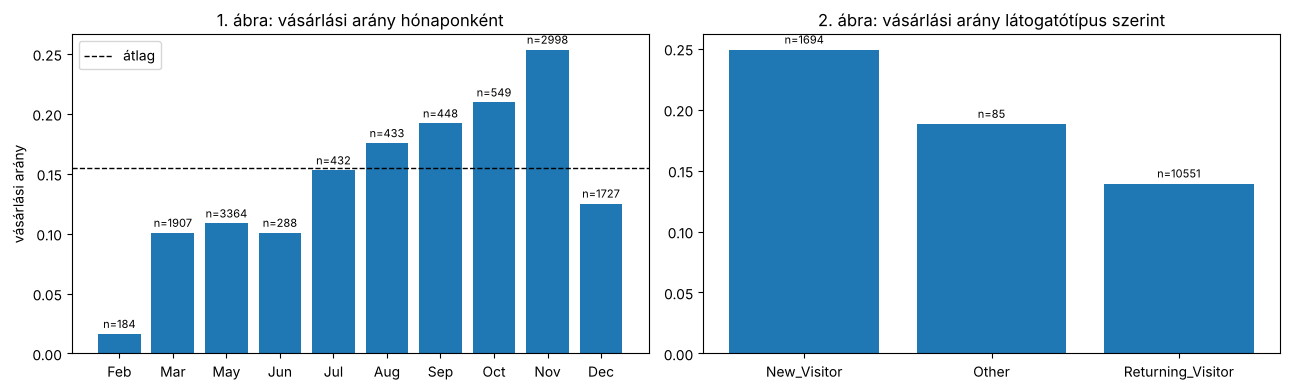

Month,Feb,Mar,May,Jun,Jul,Aug,Sep,Oct,Nov,Dec
mean,0.016,0.101,0.109,0.101,0.153,0.176,0.192,0.209,0.254,0.125
size,184.000,1907.000,3364.000,288.000,432.000,433.000,448.000,549.000,2998.000,1727.000


In [3]:
MONTHS = ["Jan", "Feb", "Mar", "Apr", "May", "Jun", "Jul", "Aug", "Sep", "Oct", "Nov", "Dec"]
g = df.groupby("Month")["Revenue"].agg(["mean", "size"]).reindex([m for m in MONTHS if m in set(df["Month"])])
fig, ax = plt.subplots(1, 2, figsize=(13, 4))
ax[0].bar(g.index, g["mean"]); ax[0].axhline(df["Revenue"].mean(), color="k", ls="--", lw=1, label="átlag")
for i, (m, r) in enumerate(g.iterrows()):
    ax[0].text(i, r["mean"] + 0.005, f"n={int(r['size'])}", ha="center", fontsize=8)
ax[0].set(title="1. ábra: vásárlási arány hónaponként", ylabel="vásárlási arány"); ax[0].legend()
v = df.groupby("VisitorType")["Revenue"].agg(["mean", "size"])
ax[1].bar(v.index, v["mean"]); ax[1].set(title="2. ábra: vásárlási arány látogatótípus szerint")
for i, (m, r) in enumerate(v.iterrows()):
    ax[1].text(i, r["mean"] + 0.005, f"n={int(r['size'])}", ha="center", fontsize=8)
plt.tight_layout(); plt.show()
g.round(3).T

**A célváltozó aránya: 15,5%** (1 908 vásárlás 12 330 munkamenetből). A pozitív osztály ritka, ezért rétegzett vágás és PR-AUC kell.

**1. ábra:** a vásárlási arány hónaponként nagyon különböző. Februárban 1,6% (184 munkamenet), novemberben 25,4% (2 998 munkamenet). Január és április hiányzik az adatból, a május és a november adja a munkamenetek több mint felét. A hónap erős jel, de egyben figyelmeztetés is: egy hónapra jellemző viselkedés nem feltétlenül általánosít más hónapokra (ezt a 8. pont végén ellenőrzöm).

**2. ábra:** az új látogatók gyakrabban vásárolnak (24,9%), mint a visszatérők (13,9%), pedig a munkamenetek 86%-a visszatérő látogatóé. A ritka „Other” kategóriának csak 85 sora van (18,8%).

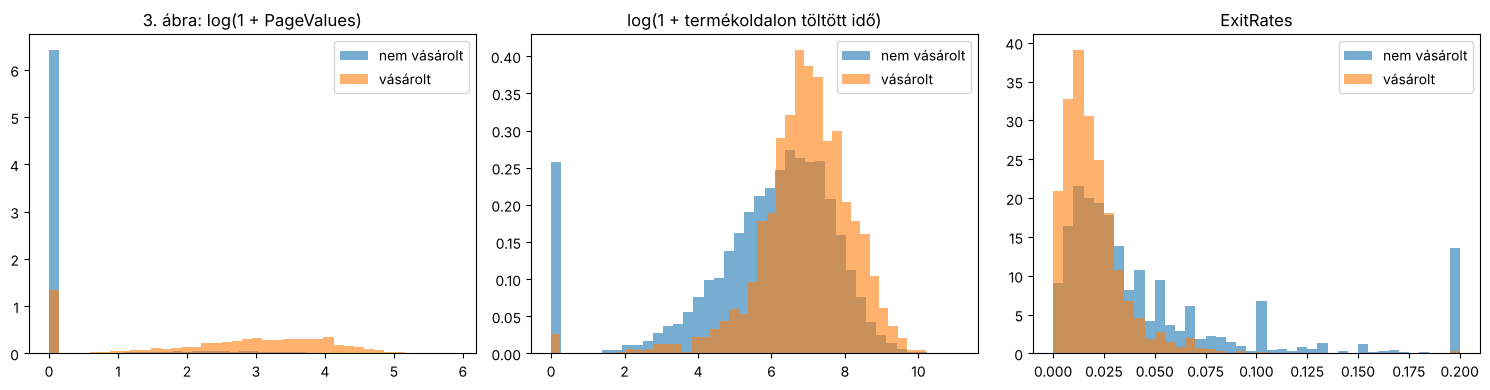

Vásárlási arány PageValues szerint:
              mean  size
pv_pozitiv             
False       0.039  9600
True        0.563  2730


In [4]:
fig, ax = plt.subplots(1, 3, figsize=(15, 4))
for lab, name in [(0, "nem vásárolt"), (1, "vásárolt")]:
    s = df[df["Revenue"] == lab]
    ax[0].hist(np.log1p(s["PageValues"]), bins=40, alpha=0.6, density=True, label=name)
    ax[1].hist(np.log1p(s["ProductRelated_Duration"]), bins=40, alpha=0.6, density=True, label=name)
    ax[2].hist(s["ExitRates"], bins=40, alpha=0.6, density=True, label=name)
ax[0].set(title="3. ábra: log(1 + PageValues)"); ax[1].set(title="log(1 + termékoldalon töltött idő)"); ax[2].set(title="ExitRates")
for a in ax: a.legend()
plt.tight_layout(); plt.show()

pv = df.assign(pv_pozitiv=df["PageValues"] > 0).groupby("pv_pozitiv")["Revenue"].agg(["mean", "size"])
print("Vásárlási arány PageValues szerint:\n", pv.round(3))

**3. ábra:** a vásárlók és a nem vásárlók eloszlása a `PageValues` mentén válik szét a legjobban. Ha a `PageValues` > 0, a vásárlási arány **56,3%**, ha 0, csak **3,9%**. A vásárlók több időt töltenek a termékoldalakon, és ritkábban lépnek ki (`ExitRates`). A `PageValues` a Google Analytics „oldalértéke”: azoknak az oldalaknak az átlagos bevétele, amelyeket vásárlás előtt megnéztek. **Ez a célváltozóból számolódik**, ezért a 4. pontban külön megvizsgálom, hogy jel-e vagy szivárgás.

## 4. Tisztítás

Hiányzó cella nincs (0 NaN), de **rejtett hiányzás** van, és van egy oszlop, amelynél a szivárgás kérdése felmerül.

In [5]:
# 4a. Duplikátumok
dup = df.duplicated()
zero_activity = (df[["Administrative", "Informational", "ProductRelated"]].sum(axis=1) <= 1) & (df["PageValues"] == 0)
print(f"Teljesen azonos sorok: {int(dup.sum())}; ebből legfeljebb 1 oldalt megnéző, 0 PageValues-ú: {int((dup & zero_activity).sum())}")
print(f"Vásárlási arány a duplikátumok közt: {df.loc[dup, 'Revenue'].mean():.1%}")

# 4b. Rejtett hiányzás: oldalt nézett meg, de az idő 0
rows = []
for page in ["Administrative", "Informational", "ProductRelated"]:
    m = (df[page] > 0) & (df[page + "_Duration"] == 0)
    rows.append({"oldaltípus": page, "oldal > 0, idő = 0 (db)": int(m.sum()),
                 "ebből pontosan 1 oldal": f"{(df.loc[m, page] == 1).mean():.0%}",
                 "vásárlási arány ezekben": round(df.loc[m, "Revenue"].mean(), 3),
                 "vásárlási arány a többiben (oldal > 0)": round(df.loc[(df[page] > 0) & ~m, "Revenue"].mean(), 3)})
pd.DataFrame(rows)

Teljesen azonos sorok: 125; ebből legfeljebb 1 oldalt megnéző, 0 PageValues-ú: 118
Vásárlási arány a duplikátumok közt: 0.0%


,oldaltípus,"oldal > 0, idő = 0 (db)",ebből pontosan 1 oldal,vásárlási arány ezekben,vásárlási arány a többiben (oldal > 0)
0,Administrative,135,97%,0.252,0.212
1,Informational,226,96%,0.212,0.235
2,ProductRelated,717,77%,0.010,0.164


**4a. Duplikátumok: megtartom.** 125 sor teljesen azonos egy másikkal. Ebből 118 legfeljebb egyoldalas, 0 `PageValues`-ú munkamenet, és egyik sem vásárolt (0%). Ezek nem adatbeviteli hibák, hanem különböző látogatók azonos, minimális viselkedése (bejött, egy oldal, kilépett). Az eldobásuk torzítaná a „visszafordulók” arányát. Ha a tanítóba és a tesztbe is jut belőlük, az nem okoz érdemi szivárgást, mert a viselkedés triviálisan felismerhető, és a címke mindegyiknél 0.

**4b. Rejtett hiányzás: „oldalt megnézett, de az idő 0”.**
- **A mechanizmus:** a Google Analytics az oldalon töltött időt a következő oldal betöltéséig méri. Az utolsó (vagy egyetlen) megnézett oldal idejét nem tudja megmérni, és 0-t ír. A termékoldalaknál 717 ilyen munkamenet van, 77%-uk pontosan 1 oldalas. A 0 itt tehát nem „0 másodperc”, hanem **„nem mérhető, mert a látogató ezen az oldalon távozott”**.
- **Jel vagy szivárgás? Jel.** Ezekben a munkamenetekben a vásárlási arány **1,0%**, a többi termékoldalas munkamenetben 16,4%. A jellemző a munkamenet során ismert, nem a célból számolódik. Ezért megtartom 0-ként, és a fa külön ágon kezeli. (Az adminisztratív és az információs oldalaknál ilyen nagy különbség nincs: 25,2% vs. 21,2% és 21,2% vs. 23,5%.)

**4c. `PageValues`: jel vagy szivárgás? Megtartom, de a hatását külön megmérem.** Az oldalérték a vásárlásokból számolódik. Ha a munkamenet saját vásárlása is beleszámít a megnézett oldalak értékébe, az szivárgás: a vásárló „megjelöli” az oldalait. Élesben viszont az oldalértéket a **korábbi** munkamenetekből számolnák, és az a jóslás pillanatában ismert. Az adatsor leírásából nem derül ki, melyik eset áll fenn. Ezért a `PageValues`-t megtartom (az adatsor készítői is jellemzőként adják meg), és a 7. pontban megmérem, mennyi múlik rajta.

**4d. Kódolás (lásd a lenti cellát):**
- Az operációs rendszer, a böngésző, a régió és a forgalomtípus **egész számmal kódolt címkék**, nem mennyiségek: a 13-as böngésző nem „nagyobb” a 2-esnél.
- **A logisztikus regresszióhoz one-hot kódolás** kell, mert különben a kódot mennyiségként, egyetlen meredekséggel kezelné. A ritka szinteket (30 sor alatt; pl. az egyik böngészőnek 1 sora van) egy „ritka” kategóriába vonom össze. Ez a kódoló a pipeline-on belül, **foldonként, csak a tanító részen** illeszkedik, így nem szivárog.
- **A fáknak sorszám-kódolás** elég: a fa küszöbökkel vág, és mélyebb vágásokkal bármelyik kódot el tudja különíteni. A one-hot sok ritka oszlopra aprózná a jelet. A hónapot naptári sorrendben kódolom (1–12), a látogatótípust 0/1/2-vel.
- **A ferde számlálókat és időtartamokat** a logisztikus modellben `log(1 + x)`-szel transzformálom, majd standardizálom (pipeline-on belül). A fáknak erre nincs szükségük.

In [6]:
# 4c. Kódolás. A kódolt kategóriák (OS, böngésző, régió, forgalomtípus) címkék, nem mennyiségek.
CAT = ["Month", "OperatingSystems", "Browser", "Region", "TrafficType", "VisitorType"]
for c in CAT:
    vc = df[c].value_counts()
    print(f"{c:17s}: {len(vc):2d} szint, a legritkább {vc.min():4d} sor")

MONTH_NUM = {m: i + 1 for i, m in enumerate(MONTHS)}
df["month_num"] = df["Month"].map(MONTH_NUM)
df["visitor_num"] = df["VisitorType"].map({"Returning_Visitor": 2, "New_Visitor": 1}).fillna(0).astype(int)

NUM = ["Administrative", "Administrative_Duration", "Informational", "Informational_Duration", "ProductRelated",
       "ProductRelated_Duration", "BounceRates", "ExitRates", "PageValues", "SpecialDay"]
SKEWED = [c for c in NUM if c not in ("BounceRates", "ExitRates", "SpecialDay")]
TREE = NUM + ["month_num", "OperatingSystems", "Browser", "Region", "TrafficType", "visitor_num", "Weekend"]

Month            : 10 szint, a legritkább  184 sor
OperatingSystems :  8 szint, a legritkább    6 sor
Browser          : 13 szint, a legritkább    1 sor
Region           :  9 szint, a legritkább  318 sor
TrafficType      : 20 szint, a legritkább    1 sor
VisitorType      :  3 szint, a legritkább   85 sor


## 5. A split előbb: zárolt teszthalmaz

**Hogyan osztottam:** 80% fejlesztési, 20% zárolt teszt, **a célváltozó szerint rétegezve** (`stratify`), rögzített seed-del (`random_state = 42`). A fejlesztési halmazon **5-fold rétegzett CV**, ugyanazzal a seed-del. **Minden modell ugyanezeket a foldokat kapja.**

**Miért nem időrendi a vágás?** Az adatban csak a hónap szerepel, év, nap és sorrend nem. A munkamenetek egyetlen évből valók, és mindegyik más felhasználóé. Így nem tudom a „múltból a jövőre” vágást megcsinálni, a hónap szerinti vágás pedig (pl. teszt = november–december) a novemberi szezont teljesen kivenné a tanítóból. Ezért rétegzett véletlen vágást választok, és **ellenőrzésként** megmérem, mennyit romlik a modell olyan hónapokon, amelyeket nem látott (8. pont vége).

In [7]:
dev, test = train_test_split(df, test_size=0.20, stratify=df["Revenue"], random_state=SEED)
dev, test = dev.reset_index(drop=True), test.reset_index(drop=True)
print(f"Fejlesztési: {len(dev)} sor, pozitív {dev['Revenue'].mean():.2%} | Zárolt teszt: {len(test)} sor, pozitív {test['Revenue'].mean():.2%}")

skf = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED)
FOLDS = list(skf.split(dev, dev["Revenue"]))
print("Pozitív arány foldonként (validációs rész):", [round(dev["Revenue"].iloc[v].mean(), 3) for _, v in FOLDS])

Fejlesztési: 9864 sor, pozitív 15.47% | Zárolt teszt: 2466 sor, pozitív 15.49%
Pozitív arány foldonként (validációs rész): [np.float64(0.155), np.float64(0.155), np.float64(0.155), np.float64(0.155), np.float64(0.155)]


**Eredmény:** 9 864 fejlesztési és 2 466 teszt-munkamenet, mindkettőben 15,5% a pozitív arány, és mind az 5 foldban is 15,5%. **Zárolva:** a `test`-hez a 9. pontig nem nyúlok. Minden illesztés (skálázás, kódolás, hangolás) foldon belül, csak a tanító részen történik.

## 6. Alapmodellek és mutatók

**A modellek:**
- **Dummy:** mindenkinek a pozitív arányt adja (PR-AUC = 0,155 lesz).
- **Logisztikus regresszió:** one-hot és log-skálázás, lásd fent.
- **Döntési fa, Random Forest, XGBoost:** sorszám-kódolással.

Hiperparamétert itt nem hangolok, az a 8. pont. **A küszöb:** a pontszámok felső 10%-a kap jelzést. Ez a kapacitásból következik, nem a teszten választott érték.

In [8]:
def metrics(y, s, thr=None):
    """y: 0/1, s: pontszám. thr=None: a küszöb a pontszámok felső 10%-a (kapacitás-szabály)."""
    thr = np.quantile(s, 1 - TOP) if thr is None else thr
    flag = (s >= thr) if np.ptp(s) > 0 else np.zeros(len(s), bool)   # állandó pontszám (dummy): senki sem kap jelzést
    return {"PR-AUC": average_precision_score(y, s), "ROC-AUC": roc_auc_score(y, s),
            "bal. pontosság": balanced_accuracy_score(y, flag),
            "top10% találati arány": y[flag].mean() if flag.any() else np.nan,
            "top10% lefedettség": y[flag].sum() / y.sum(),
            "nyers pontosság": accuracy_score(y, flag)}

def cv(make_model, cols, data=None, folds=None, add=None):
    """Out-of-fold pontszámok és foldonkénti mutatók UGYANAZOKON a foldokon."""
    data = dev if data is None else data
    folds = FOLDS if folds is None else folds
    if add is not None:
        data = add(data)
    oof, rows = np.zeros(len(data)), []
    for k, (tr, va) in enumerate(folds):
        m = make_model().fit(data.iloc[tr][cols], data["Revenue"].iloc[tr])
        oof[va] = m.predict_proba(data.iloc[va][cols])[:, 1]
        rows.append({"fold": k, **metrics(data["Revenue"].values[va], oof[va])})
    return oof, pd.DataFrame(rows).set_index("fold")

def summary(res):
    return pd.DataFrame({n: {c: f"{t[c].mean():.3f} ± {t[c].std():.3f}" for c in t.columns} for n, t in res.items()}).T

def logreg(cols_num, C=1.0):
    skew = [c for c in cols_num if c in SKEWED]
    rest = [c for c in cols_num if c not in SKEWED]
    ct = ColumnTransformer([
        ("skew", make_pipeline(FunctionTransformer(np.log1p), StandardScaler()), skew),
        ("num", StandardScaler(), rest),
        ("cat", OneHotEncoder(min_frequency=30, handle_unknown="infrequent_if_exist"), CAT),
        ("bin", "passthrough", ["Weekend"])])
    return make_pipeline(ct, LogisticRegression(C=C, max_iter=3000))

def xgb(**kw):
    p = dict(n_estimators=400, learning_rate=0.05, max_depth=4, subsample=0.8, colsample_bytree=0.8,
             eval_metric="logloss", n_jobs=-1, random_state=SEED); p.update(kw)
    return XGBClassifier(**p)

LR_COLS = NUM + CAT + ["Weekend"]
MODELS = {
    "Dummy (arány)":     (lambda: DummyClassifier(strategy="prior"), TREE),
    "Logisztikus":       (lambda: logreg(NUM), LR_COLS),
    "Döntési fa":        (lambda: DecisionTreeClassifier(min_samples_leaf=20, random_state=SEED), TREE),
    "Random Forest":     (lambda: RandomForestClassifier(n_estimators=400, min_samples_leaf=2, n_jobs=-1, random_state=SEED), TREE),
    "XGBoost":           (lambda: xgb(), TREE),
}
OOF, RES = {}, {}
for name, (mk, cols) in MODELS.items():
    OOF[name], RES[name] = cv(mk, cols)
summary(RES)

,PR-AUC,ROC-AUC,bal. pontosság,top10% találati arány,top10% lefedettség,nyers pontosság
Dummy (arány),0.155 ± 0.000,0.500 ± 0.000,0.500 ± 0.000,nan ± nan,0.000 ± 0.000,0.845 ± 0.000
Logisztikus,0.689 ± 0.024,0.916 ± 0.003,0.722 ± 0.016,0.734 ± 0.042,0.476 ± 0.027,0.892 ± 0.008
Döntési fa,0.671 ± 0.025,0.890 ± 0.004,0.730 ± 0.017,0.740 ± 0.050,0.492 ± 0.028,0.895 ± 0.010
Random Forest,0.746 ± 0.021,0.929 ± 0.004,0.738 ± 0.014,0.774 ± 0.037,0.502 ± 0.024,0.900 ± 0.007
XGBoost,0.750 ± 0.021,0.933 ± 0.004,0.740 ± 0.013,0.780 ± 0.035,0.506 ± 0.022,0.901 ± 0.007


**Mit látok (CV, átlag ± szórás az 5 fold között):**
- **Dummy:** PR-AUC 0,155 (a pozitív arány), kiegyensúlyozott pontosság 0,500, de nyers pontossága **0,845**. Ez a nyers pontosság csapdája számokkal. (A dummy minden munkamenetnek ugyanazt a pontszámot adja, ezért senkit sem jelez, a találati aránya nem értelmezhető: `nan`.)
- **Logisztikus:** PR-AUC **0,689 ± 0,024**, a felső 10% találati aránya 0,734. A **döntési fa** gyengébb (0,671).
- **Random Forest:** 0,746, **XGBoost: 0,750 ± 0,021**. A felső 10% találati aránya 0,780, vagyis a jelzettek 78%-a vásárol, és a vásárlók 50,6%-át fedjük le.
- **XGBoost vs. logisztikus:** a különbség 0,061 PR-AUC, ami a foldok közti szórás (≈ 0,02) háromszorosa. Ez megfelel a feladatleírás előzetes mérésének („az XGBoost erősen veri a logisztikust”).
- Az RF és az XGBoost közti 0,004 **kisebb a szórásnál**, így ezt **nem** nevezem valódi különbségnek.

In [9]:
# Konfúziós mátrix a kapacitás-küszöbnél (a felső 10% kap jelzést), out-of-fold, a fejlesztési adaton
y = dev["Revenue"].values
cms = {}
for name in ["Logisztikus", "XGBoost"]:
    s = OOF[name]; flag = s >= np.quantile(s, 1 - TOP)
    tn, fp, fn, tp = confusion_matrix(y, flag).ravel()
    cms[name] = {"TP (jelzett vásárló)": tp, "FP (álriasztás)": fp, "FN (kihagyott vásárló)": fn, "TN": tn}
display(pd.DataFrame(cms).T)
flag05 = OOF["XGBoost"] >= 0.5
print(f"Összevetés: XGBoost 0,5-ös küszöbbel — jelzett arány {flag05.mean():.1%}, bal. pontosság "
      f"{balanced_accuracy_score(y, flag05):.3f}, nyers pontosság {accuracy_score(y, flag05):.3f}")

,TP (jelzett vásárló),FP (álriasztás),FN (kihagyott vásárló),TN
Logisztikus,727,260,799,8078
XGBoost,766,221,760,8117


Összevetés: XGBoost 0,5-ös küszöbbel — jelzett arány 12.7%, bal. pontosság 0.781, nyers pontosság 0.905


**Konfúziós mátrix** (out-of-fold, a teljes fejlesztési adat, a felső 10%-os küszöb):
- **XGBoost:** 766 megtalált vásárló (TP), 221 álriasztás (FP), 760 kihagyott vásárló (FN).
- **Logisztikus:** 727 TP, 260 FP, 799 FN.

A kapacitás miatt a vásárlók kb. fele kimarad. A 10%-os keret erre a 15,5%-os pozitív arányra **a felső határ**: a vásárlók legfeljebb 65%-a fér bele. **A küszöb hatása:** 0,5-ös küszöbnél az XGBoost a munkamenetek 12,7%-át jelezné, a kiegyensúlyozott pontosság 0,781, a nyers pontosság 0,905 lenne. A nyers pontosság alig változik, miközben a jelzések száma és a lefedettség igen. Ezért a küszöböt a kapacitás dönti el, nem a pontosság.

## 7. Visszacsatolási kör: hibaelemzés → hipotézis → új jellemző → ugyanazok a foldok

In [10]:
# Hibaelemzés: a kihagyott vásárlók (FN) és a megtalált vásárlók (TP) összevetése, XGBoost, top 10% küszöb
s = OOF["XGBoost"]; flag = s >= np.quantile(s, 1 - TOP)
grp = np.select([(y == 1) & flag, (y == 1) & ~flag, (y == 0) & flag], ["TP", "FN", "FP"], "TN")
prof = dev.assign(csoport=grp).groupby("csoport").agg(
    db=("Revenue", "size"), PageValues_pozitív=("PageValues", lambda x: (x > 0).mean()),
    PageValues_medián=("PageValues", "median"), termékoldal_medián=("ProductRelated", "median"),
    termékidő_medián=("ProductRelated_Duration", "median"), ExitRates_medián=("ExitRates", "median"),
    új_látogató=("VisitorType", lambda x: (x == "New_Visitor").mean()), november=("Month", lambda x: (x == "Nov").mean()))
display(prof.loc[["TP", "FN", "FP", "TN"]].round(3))

pv0 = dev["PageValues"] == 0
print(f"A PageValues = 0 munkamenetek a dev {pv0.mean():.0%}-a; a vásárlók {dev.loc[pv0, 'Revenue'].sum() / dev['Revenue'].sum():.0%}-a ilyen.")
print(f"PR-AUC csak a PageValues = 0 munkameneteken: XGBoost {average_precision_score(y[pv0], s[pv0]):.3f} "
      f"(alap arány {y[pv0].mean():.3f}); PageValues > 0-n: {average_precision_score(y[~pv0], s[~pv0]):.3f} (alap arány {y[~pv0].mean():.3f})")

,db,PageValues_pozitív,PageValues_medián,termékoldal_medián,termékidő_medián,ExitRates_medián,új_látogató,november
csoport,,,,,,,,
TP,766,1.000,35.981,21.0,808.333,0.012,0.325,0.343
FN,760,0.624,4.449,39.0,1537.275,0.020,0.111,0.425
FP,221,0.995,22.096,29.0,1114.733,0.016,0.140,0.430
TN,8117,0.090,0.000,15.0,490.833,0.029,0.121,0.207


A PageValues = 0 munkamenetek a dev 78%-a; a vásárlók 19%-a ilyen.
PR-AUC csak a PageValues = 0 munkameneteken: XGBoost 0.165 (alap arány 0.037); PageValues > 0-n: 0.824 (alap arány 0.565)


**Milyen hibákat néztem meg:** az XGBoost out-of-fold jóslatain a megtalált (TP) és a kihagyott (FN) vásárlókat hasonlítottam össze.
- **A megtalált vásárlók** 100%-ánál `PageValues` > 0 (medián 36,0).
- **A kihagyott vásárlóknál** ez csak 62,4% (medián 4,4). Ők **több** termékoldalt néznek meg (medián 39 vs. 21), és **kétszer annyi** időt töltenek ott (1 537 vs. 808 s). Kevesebb köztük az új látogató (11% vs. 33%), és több a novemberi (43% vs. 34%).
- **Számszerűen:** a `PageValues` = 0 munkamenetek a dev 78%-át teszik ki, és a vásárlók 19%-a ilyen. Ezen a csoporton a modell PR-AUC-ja csak **0,165** (alap arány 0,037), a `PageValues` > 0 csoporton 0,824.

**Hipotézis:** a modell szinte csak a `PageValues`-ra támaszkodik. Azoknál a vásárlóknál, akiknek alacsony vagy nulla az oldalértékük, a vásárlási szándék a **böngészés intenzitásában** rejlik: mennyi időt tölt egy termékoldalon, mekkora a termékoldalak aránya, mennyire marad az oldalon. Ezek **két oszlopból számolt** mennyiségek (hányados, szorzat, különbség), amelyeket a fa tengelyirányú vágásokkal nehezen állít elő.

**Az új jellemzők** (mind a munkamenet adataiból, egyik sem a célból):
- `prod_sec_per_page` = termékoldalon töltött idő / termékoldalak száma;
- `prod_share` = termékoldalak / összes oldal, és `total_pages`;
- `pv_per_prod_page` = PageValues / (termékoldalak + 1);
- `pv_x_stay` = PageValues × (1 − ExitRates);
- `exit_minus_bounce` = ExitRates − BounceRates;
- `pv_pos` = 1, ha PageValues > 0. Ez egyetlen jelző, a feladatleírás Bank Churn-példájának (`products ≥ 3`) megfelelője.

**Döntési szabály:** javulásnak csak azt nevezem, ami **minden foldon** javít, és az átlaga nagyobb a foldok közti szórásnál.

In [11]:
def add_fe(t):
    """Két oszlopból számolt jellemzők (a fa tengelyirányú vágásokkal nehezen tanulja meg őket); NEM a célból."""
    t = t.copy()
    pages = t["Administrative"] + t["Informational"] + t["ProductRelated"]
    t["total_pages"] = pages
    t["prod_share"] = t["ProductRelated"] / pages.replace(0, np.nan)
    t["prod_sec_per_page"] = t["ProductRelated_Duration"] / t["ProductRelated"].replace(0, np.nan)
    t["pv_per_prod_page"] = t["PageValues"] / (t["ProductRelated"] + 1)
    t["pv_x_stay"] = t["PageValues"] * (1 - t["ExitRates"])
    t["exit_minus_bounce"] = t["ExitRates"] - t["BounceRates"]
    t["pv_pos"] = (t["PageValues"] > 0).astype(int)
    for c in ["prod_share", "prod_sec_per_page"]:          # 0 oldalnál nincs értelme: 0 + külön jelző a pages=0-ra
        t[c] = t[c].fillna(0)
    return t

FE = ["total_pages", "prod_share", "prod_sec_per_page", "pv_per_prod_page", "pv_x_stay", "exit_minus_bounce", "pv_pos"]
FE_LR_SKEW = ["total_pages", "prod_sec_per_page", "pv_per_prod_page", "pv_x_stay"]
SKEWED += FE_LR_SKEW

EXPS = {
    "Logisztikus + pv_pos":  (lambda: logreg(NUM + ["pv_pos"]), LR_COLS + ["pv_pos"]),
    "Logisztikus + FE":      (lambda: logreg(NUM + FE), LR_COLS + FE),
    "XGBoost + pv_pos":      (lambda: xgb(), TREE + ["pv_pos"]),
    "XGBoost + FE":          (lambda: xgb(), TREE + FE),
    "XGBoost PageValues nélkül": (lambda: xgb(), [c for c in TREE if c != "PageValues"]),
}
for name, (mk, cols) in EXPS.items():
    OOF[name], RES[name] = cv(mk, cols, add=add_fe)
summary({k: RES[k] for k in ["Logisztikus", "Logisztikus + pv_pos", "Logisztikus + FE", "XGBoost", "XGBoost + pv_pos",
                              "XGBoost + FE", "XGBoost PageValues nélkül"]})

,PR-AUC,ROC-AUC,bal. pontosság,top10% találati arány,top10% lefedettség,nyers pontosság
Logisztikus,0.689 ± 0.024,0.916 ± 0.003,0.722 ± 0.016,0.734 ± 0.042,0.476 ± 0.027,0.892 ± 0.008
Logisztikus + pv_pos,0.700 ± 0.024,0.916 ± 0.003,0.730 ± 0.015,0.754 ± 0.039,0.489 ± 0.025,0.896 ± 0.008
Logisztikus + FE,0.712 ± 0.021,0.922 ± 0.003,0.731 ± 0.011,0.757 ± 0.029,0.491 ± 0.018,0.897 ± 0.006
XGBoost,0.750 ± 0.021,0.933 ± 0.004,0.740 ± 0.013,0.780 ± 0.035,0.506 ± 0.022,0.901 ± 0.007
XGBoost + pv_pos,0.750 ± 0.020,0.933 ± 0.004,0.740 ± 0.015,0.781 ± 0.039,0.507 ± 0.025,0.902 ± 0.008
XGBoost + FE,0.747 ± 0.019,0.932 ± 0.005,0.738 ± 0.013,0.775 ± 0.035,0.503 ± 0.022,0.900 ± 0.007
XGBoost PageValues nélkül,0.379 ± 0.019,0.786 ± 0.009,0.613 ± 0.012,0.449 ± 0.033,0.292 ± 0.021,0.835 ± 0.006


In [12]:
def paired(base, new, metric="PR-AUC"):
    d = RES[new][metric] - RES[base][metric]          # + = az új jobb
    return {"alap → új": f"{base} → {new}", "foldonként": " ".join(f"{v:+.3f}" for v in d),
            "átlag ± szórás": f"{d.mean():+.4f} ± {d.std():.4f}", "minden foldon javít": bool((d > 0).all()),
            "valódi (átlag > szórás és minden fold)": bool((d > 0).all() and d.mean() > d.std())}

pd.DataFrame([paired("Logisztikus", "Logisztikus + pv_pos"), paired("Logisztikus", "Logisztikus + FE"),
              paired("XGBoost", "XGBoost + pv_pos"), paired("XGBoost", "XGBoost + FE"),
              paired("XGBoost", "XGBoost PageValues nélkül")])

,alap → új,foldonként,átlag ± szórás,minden foldon javít,valódi (átlag > szórás és minden fold)
0,Logisztikus → Logisztikus + pv_pos,+0.019 +0.013 +0.012 +0.016 -0.003,+0.0114 ± 0.0085,False,False
1,Logisztikus → Logisztikus + FE,+0.035 +0.027 +0.021 +0.017 +0.017,+0.0236 ± 0.0077,True,True
2,XGBoost → XGBoost + pv_pos,-0.002 +0.003 +0.001 -0.003 +0.001,-0.0001 ± 0.0024,False,False
3,XGBoost → XGBoost + FE,+0.002 -0.004 +0.000 -0.003 -0.008,-0.0024 ± 0.0037,False,False
4,XGBoost → XGBoost PageValues nélkül,-0.373 -0.382 -0.352 -0.366 -0.382,-0.3711 ± 0.0125,False,False


**Eredmények (páros különbség PR-AUC-ban, új − alap):**
- **Logisztikus + `pv_pos`:** +0,011 ± 0,009, 5 foldból 4-en javít. Az átlag nagyobb a szórásnál, de nem minden foldon javít, ezért **határeset, nem nevezem valódinak**.
- **Logisztikus + teljes jellemzőcsomag:** **+0,024 ± 0,008, mind az 5 foldon**. Ez **valódi javulás** (0,689 → 0,712).
- **XGBoost + `pv_pos`:** −0,000 ± 0,002, és **XGBoost + teljes csomag:** −0,002 ± 0,004. **Egyik sem segített**, a csomag inkább kicsit rontott.
- **Válasz a feladat kérdésére: nem találtam olyan jellemzőt, ami az XGBoostnak segít.** A két oszlopból számolt hányadosok sem segítettek. Ugyanaz a mintázat jött ki, mint a feladatleírás előzetes méréseiben: a feature engineering a lineáris modellnek segít, a fának nem. Az ok valószínűleg az, hogy az XGBoost a `PageValues`, az `ExitRates` és az idők kombinációit 400 fa alatt már összerakta, a kihagyott vásárlók pedig olyanok, akiknek a viselkedése a nem vásárlókéhoz hasonlít (lásd az FP és az FN profilját).

**A `PageValues` szerepe (a 4c. pont kérdése):** nélküle az XGBoost PR-AUC-ja **0,750-ről 0,379-re** esik (−0,371 ± 0,013). A modell teljesítményének kb. fele ezen az egy, a célból számolt oszlopon múlik. Ha élesben az oldalérték nem a korábbi munkamenetekből számolódna, vagy a saját vásárlás is benne van, akkor a valódi teljesítmény a 0,379-hez lenne közelebb. Ezt a korlátok között is jelzem.

## 8. Hangolás a legjobb modellre (XGBoost), beágyazott CV-vel

**Mit csinálok:** a jellemzőcsomag nem segített az XGBoostnak, ezért az alap jellemzőkkel hangolok. A **véletlen keresés** (25 kombináció a fa mélységére, a tanulási rátára, a fák számára, a regularizációra és a mintavételezésre) **csak a külső fold tanító részén** fut, belső 3-fold CV-vel. A kiválasztott beállítás eredményét a külső validációs fold méri, **amelyet a keresés nem látott**. A külső foldok ugyanazok, mint mindenhol, így a páros különbség az alapbeállításhoz képest tisztességes.

In [13]:
# Beágyazott (nested) CV: a keresés csak a külső fold tanító részén fut (belső 3-fold), az eredményt a külső
# validációs fold méri, amit a keresés nem látott. Ugyanazok a külső foldok, mint mindenhol.
BEST_COLS = TREE + FE if RES["XGBoost + FE"]["PR-AUC"].mean() > RES["XGBoost"]["PR-AUC"].mean() else TREE
grid = {"n_estimators": [200, 400, 800], "learning_rate": [0.02, 0.05, 0.1], "max_depth": [2, 3, 4, 6],
        "min_child_weight": [1, 3, 10], "subsample": [0.7, 0.8, 1.0], "colsample_bytree": [0.6, 0.8, 1.0],
        "reg_lambda": [1, 5, 20]}
data_fe = add_fe(dev)
oof_t, rows, chosen = np.zeros(len(dev)), [], []
for k, (tr, va) in enumerate(FOLDS):
    search = RandomizedSearchCV(xgb(), grid, n_iter=25, scoring="average_precision", random_state=SEED,
                                cv=StratifiedKFold(3, shuffle=True, random_state=SEED), n_jobs=1)
    search.fit(data_fe.iloc[tr][BEST_COLS], data_fe["Revenue"].iloc[tr])
    oof_t[va] = search.predict_proba(data_fe.iloc[va][BEST_COLS])[:, 1]
    rows.append({"fold": k, **metrics(y[va], oof_t[va])}); chosen.append(search.best_params_)
OOF["XGBoost hangolt (nested)"], RES["XGBoost hangolt (nested)"] = oof_t, pd.DataFrame(rows).set_index("fold")
base_name = "XGBoost + FE" if BEST_COLS != TREE else "XGBoost"
display(pd.DataFrame(chosen))
pd.DataFrame([paired(base_name, "XGBoost hangolt (nested)")])

,subsample,reg_lambda,n_estimators,min_child_weight,max_depth,learning_rate,colsample_bytree
0,1.0,1,200,3,4,0.02,1.0
1,1.0,1,200,3,4,0.02,1.0
2,0.7,20,400,3,3,0.02,0.8
3,0.7,1,200,1,6,0.02,0.8
4,1.0,1,200,3,4,0.02,1.0


,alap → új,foldonként,átlag ± szórás,minden foldon javít,valódi (átlag > szórás és minden fold)
0,XGBoost → XGBoost hangolt (nested),+0.009 +0.004 -0.008 -0.004 +0.002,+0.0007 ± 0.0068,False,False


**Eredmény:** a hangolt modell páros különbsége az alapbeállításhoz képest **+0,001 ± 0,007**. 5 foldból csak 3-on javít, és az átlag jóval kisebb a szórásnál. **A hangolás nem javított érdemben.** A keresés minden foldban a legkisebb tanulási rátát (0,02) választotta, de a többi paraméter foldonként más lett (mélység 3–6, 200–400 fa). Ez is azt jelzi, hogy a teljesítmény ezen a tartományon „lapos”. **Döntés:** a szabály szerint az **egyszerűbbet tartom meg**, vagyis az alapbeállítású XGBoostot.

In [14]:
# Időbeli robusztusság (csak ellenőrzés): ha a validációs fold egy egész HÓNAP, amit a modell nem látott
gkf = GroupKFold(n_splits=5)
mfolds = list(gkf.split(dev, dev["Revenue"], groups=dev["Month"]))
_, r_month = cv(lambda: xgb(), BEST_COLS, folds=mfolds, add=add_fe)
r_month.index = ["+".join(sorted(dev["Month"].iloc[v].unique(), key=MONTHS.index)) for _, v in mfolds]
display(r_month[["PR-AUC", "top10% találati arány"]].round(3))
print(f"Hónap-csoportos CV PR-AUC: {r_month['PR-AUC'].mean():.3f} ± {r_month['PR-AUC'].std():.3f} "
      f"(rétegzett véletlen CV ugyanezzel a modellel: {RES[base_name]['PR-AUC'].mean():.3f})")

,PR-AUC,top10% találati arány
May,0.824,0.745
Nov,0.660,0.767
Mar,0.813,0.747
Jun+Dec,0.708,0.728
Feb+Jul+Aug+Sep+Oct,0.683,0.758


Hónap-csoportos CV PR-AUC: 0.737 ± 0.076 (rétegzett véletlen CV ugyanezzel a modellel: 0.750)


**Időbeli ellenőrzés:** ha a validációs fold egész hónapokból áll, amelyeket a modell nem látott, a PR-AUC **0,737 ± 0,076** a rétegzett CV 0,750-ével szemben. Átlagban alig rosszabb, de a hónapok között nagy a szórás. A legrosszabb a **november (0,660)**, amikor a legtöbben vásárolnak, és a viselkedés eltér a többi hónaptól. A felső 10% találati aránya viszont minden hónapcsoportban 0,73–0,77 között marad. A véletlen vágás tehát nem fest lényegesen hamis képet az átlagról, de egy szezonális hónapra a modell bizonytalanabb.

## 9. Záró teszt: egyszer

**Az előre rögzített szabály:** a legnagyobb CV PR-AUC nyer; ha a jobbik csak a szóráson belül jobb, az egyszerűbb marad. Így a végső modell az **alapbeállítású XGBoost az alap jellemzőkkel**. A küszöb a **fejlesztési adat out-of-fold pontszámainak** felső 10%-ánál van (0,617), nem a tesztből számolom. A modell a teljes fejlesztési adaton tanul. Összevetésnek a logisztikus alapmodell és a dummy is a teszten jósol.

In [15]:
# Előre rögzített szabály: a legnagyobb CV PR-AUC; ha a jobbik csak a foldok közti szóráson belül jobb,
# az egyszerűbb (alapbeállítású, kevesebb jellemzős) változat marad.
tuned_real = paired(base_name, "XGBoost hangolt (nested)")["valódi (átlag > szórás és minden fold)"]
if tuned_real:
    final_search = RandomizedSearchCV(xgb(), grid, n_iter=25, scoring="average_precision", random_state=SEED,
                                      cv=StratifiedKFold(3, shuffle=True, random_state=SEED), n_jobs=1)
    final_search.fit(data_fe[BEST_COLS], data_fe["Revenue"]); FINAL_PARAMS = final_search.best_params_
    final_oof = OOF["XGBoost hangolt (nested)"]
else:
    FINAL_PARAMS = {}; final_oof = OOF[base_name]
FINAL_NAME = base_name + (" hangolt" if tuned_real else "")
THR = np.quantile(final_oof, 1 - TOP)          # a küszöb a dev out-of-fold pontszámaiból, NEM a tesztből
print("Végső modell:", FINAL_NAME, "| paraméterek:", FINAL_PARAMS or "alapbeállítás", f"| küszöb: {THR:.3f}")

Végső modell: XGBoost | paraméterek: alapbeállítás | küszöb: 0.617


In [16]:
# A záró teszt EGYSZER
test_fe = add_fe(test)
yt = test["Revenue"].values
final = xgb(**FINAL_PARAMS).fit(data_fe[BEST_COLS], data_fe["Revenue"])
lr = logreg(NUM).fit(dev[LR_COLS], dev["Revenue"])
lr_thr = np.quantile(OOF["Logisztikus"], 1 - TOP)
TEST_S = {FINAL_NAME: (final.predict_proba(test_fe[BEST_COLS])[:, 1], THR),
          "Logisztikus (alap)": (lr.predict_proba(test[LR_COLS])[:, 1], lr_thr),
          "Dummy": (np.full(len(test), dev["Revenue"].mean()), 1.0)}
tab = {n: metrics(yt, s, thr) | {"jelzett arány": (s >= thr).mean()} for n, (s, thr) in TEST_S.items()}
display(pd.DataFrame(tab).T.round(3))
tn, fp, fn, tp = confusion_matrix(yt, TEST_S[FINAL_NAME][0] >= THR).ravel()
print(f"Konfúziós mátrix ({FINAL_NAME}, teszt): TP {tp}, FP {fp}, FN {fn}, TN {tn}")

,PR-AUC,ROC-AUC,bal. pontosság,top10% találati arány,top10% lefedettség,nyers pontosság,jelzett arány
XGBoost,0.738,0.929,0.731,0.797,0.484,0.901,0.094
Logisztikus (alap),0.665,0.911,0.719,0.737,0.469,0.892,0.099
Dummy,0.155,0.500,0.500,NaN,0.000,0.845,0.000


Konfúziós mátrix (XGBoost, teszt): TP 185, FP 47, FN 197, TN 2037


In [17]:
# Bootstrap konfidenciaintervallum (2000 újramintázás, visszatevéssel) a PR-AUC-ra és a különbségre
rng = np.random.default_rng(SEED)
B, n = 2000, len(yt)
bs = {k: [] for k in TEST_S}
for _ in range(B):
    ix = rng.integers(0, n, n)
    if yt[ix].sum() == 0: continue
    for k, (s, _) in TEST_S.items():
        bs[k].append(average_precision_score(yt[ix], s[ix]))
ci = lambda v: f"{np.mean(v):.3f} [{np.percentile(v, 2.5):.3f}; {np.percentile(v, 97.5):.3f}]"
out = {k: ci(v) for k, v in bs.items()}
out[f"{FINAL_NAME} − Logisztikus"] = ci(np.subtract(bs[FINAL_NAME], bs["Logisztikus (alap)"]))
out[f"{FINAL_NAME} − Dummy"] = ci(np.subtract(bs[FINAL_NAME], bs["Dummy"]))
pd.Series(out, name="PR-AUC [95% CI]").to_frame()

,PR-AUC [95% CI]
XGBoost,0.738 [0.694; 0.780]
Logisztikus (alap),0.666 [0.613; 0.718]
Dummy,0.155 [0.141; 0.169]
XGBoost − Logisztikus,0.072 [0.042; 0.105]
XGBoost − Dummy,0.583 [0.543; 0.622]


**Eredmény a teszten:**
- **XGBoost PR-AUC: 0,738 [0,694; 0,780]** (95%-os bootstrap-intervallum, 2000 újramintázás visszatevéssel). A CV-ben 0,750 ± 0,021 volt, a teszt ezen belül van, tehát a CV-becslés nem volt túl optimista.
- **Logisztikus alapmodell:** 0,666 [0,613; 0,718]. **A különbség 0,072 [0,042; 0,105]**, az intervallum nem érinti a 0-t, vagyis az XGBoost valóban jobb. A dummy: 0,155.
- **Az üzemi pontban** (a dev-ből rögzített küszöbbel a teszt 9,4%-a kap jelzést): a jelzettek **79,7%-a** vásárol, a vásárlók **48,4%-át** érjük el, a kiegyensúlyozott pontosság 0,731.
- **Konfúziós mátrix:** 185 TP, 47 FP, 197 FN, 2 037 TN. Öt jelzésből négy valódi vásárlóhoz kerül. A vásárlók fele azonban a kapacitás és a `PageValues` = 0 csoport gyenge felismerése miatt kimarad.
- **A nyers pontosság** az XGBoostnál 0,901, a dummynál 0,845. A 6 százalékpontos különbség elfedi, hogy az egyik 185 vásárlót talál meg, a másik egyet sem.

## 10. Korlátok

1. A modell teljesítményének kb. fele a `PageValues`-on múlik (nélküle a CV PR-AUC 0,750 helyett 0,379), ez pedig a vásárlásokból számolódik, így ha élesben nem kizárólag korábbi munkamenetekből számolnák, az eredmény szivárgás miatt túlbecsült.
2. Az adatban csak hónap van, év és sorrend nincs, ezért időrendi vágás helyett rétegzett véletlen vágást használtam, és a hónap-csoportos ellenőrzés szerint egy nem látott szezonális hónapra (november: 0,660) a modell lényegesen gyengébb.
3. A jellemzők a munkamenet végén ismert összesítések (oldalszám, idő, kilépési arány), így egy valódi, munkamenet közbeni chat-ajánlásnál a modell kevesebb információból dolgozna, és az új jellemzőim, valamint a hangolás az XGBoostnak nem hoztak mérhető javulást.